# Gabriele's Notebook

In this notebook i test several models

In [30]:
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
from plotly import graph_objects as go

# Utils
from tqdm.notebook import tqdm
from tabulate import tabulate

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch

# Custom modules
import Models_regr as Models
import Dataset
import utils


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

We first load the dataframe from the parquet file.

In [57]:
df = pd.read_parquet('../Data/FI-2010-Cleaned/NoAuctionZscore/WRT1V_NoAuction_Zscore.parquet')
df.drop(columns=['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], inplace=True)
df = df.head(100000)
target_cols = ['MP']

# Basic feature extraction
# df = utils.FeaturesExtractionLOB(df).extract()
df["MP"] = (df["P_Ask_1"] + df["P_Bid_1"]) / 2

df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,MP
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792


In [59]:
# Split the dataframe into train and test
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
df_train, df_val = train_test_split(df_train, test_size=0.2, shuffle=False)

# Standardize the data
scaler = StandardScaler()
scaler.set_output()
df_train[df_train.columns] = scaler.fit_transform(df_train)
df_val[df_val.columns] = scaler.transform(df_val)
df_test[df_test.columns] = scaler.transform(df_test)

# Split covariates and response variable(s)
X_train, y_train = df_train.drop(columns=target_cols).values , df_train[target_cols].values
X_val, y_val     = df_val.drop(columns=target_cols).values   , df_val[target_cols].values
X_test, y_test   = df_test.drop(columns=target_cols).values  , df_test[target_cols].values

# Standardize the covariates
# scaler_X = StandardScaler()
# X_train = scaler_X.fit_transform(X_train)
# X_val = scaler_X.transform(X_val)
# X_test = scaler_X.transform(X_test)

# Build tensors 
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device)

# Build TimeSeriesDataset
SEQ_LEN_X = 10
SEQ_LEN_Y = 1
OFFSET = 10
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)

# Build TimeSeriesLoader
BATCH_SIZE = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [60]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 63980 samples
Test dataset: 19980 samples


## Models

### Aragosta

In [61]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

The model has 237249 parameters


Training:   0%|          | 0/3 [00:00<?, ?it/s]

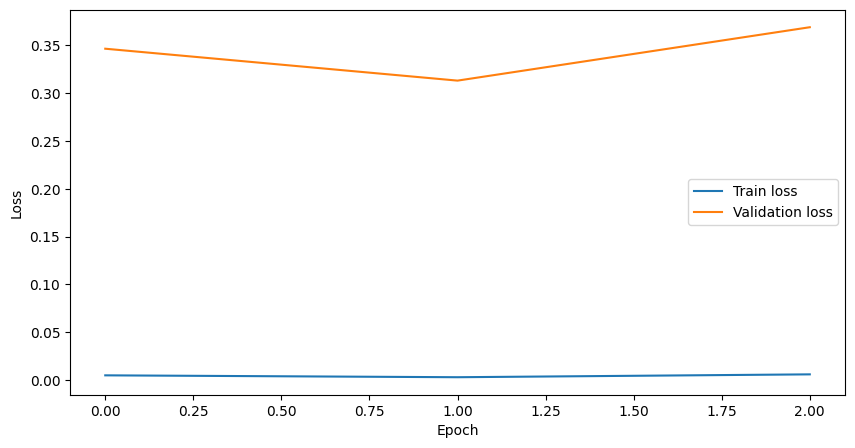

In [62]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 64

# LSTM
LSTM_SIZE = 64
LSTM_LAYERS = 2

# CNN
CONV_CHANNELS = 64
INCEPTION_CHANNELS = 64

# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = Models.Aragosta(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    conv_channels = CONV_CHANNELS,
    inception_channels = INCEPTION_CHANNELS,
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [63]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)-0.1

print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')
print(f'MSE: {torch.nn.MSELoss()(torch.tensor(true), torch.tensor(pred)).item():.4f}')

fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
fig.show()

sMAPE: 22.7%
MSE: 0.0330


### Basic LSTM

In [64]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

The model has 81665 parameters


Training:   0%|          | 0/3 [00:00<?, ?it/s]

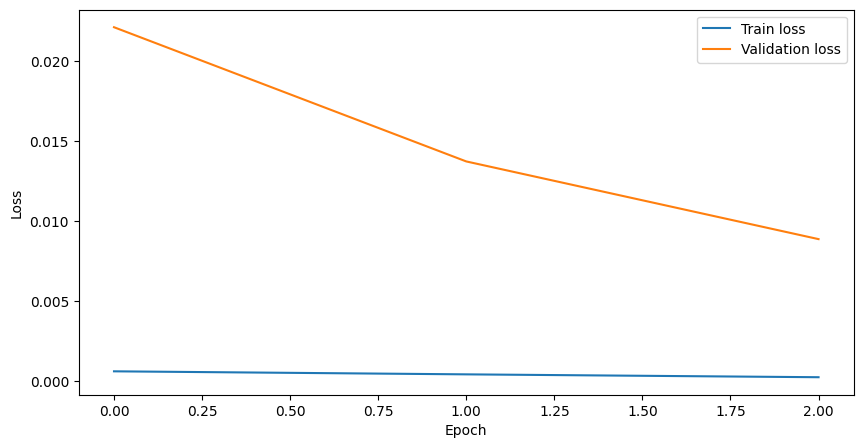

In [65]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.0
# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = Models.LSTM(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [66]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')
print(f'MSE: {torch.nn.MSELoss()(torch.tensor(true), torch.tensor(pred)).item():.4f}')

fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
fig.show()

sMAPE: 2.9%
MSE: 0.0009


### Joel's model

In [ ]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
HIDDEN_SIZE = 64
NUM_LAYERS = 2
OUTPUT_SIZE = y_train.shape[1]
DROPOUT = 0.0
# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = Models.LSTM1(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

In [ ]:
print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

In [42]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
fig.show()

### Astice

<img src="../astice.png" width="200" >

The model has 80685 parameters


Training:   0%|          | 0/3 [00:00<?, ?it/s]

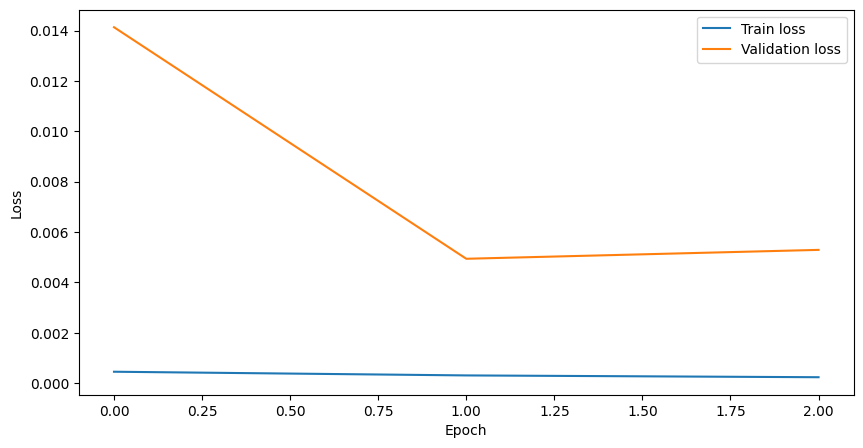

In [67]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 64

# LSTM
LSTM_SIZE = 64
LSTM_LAYERS = 2

# CMM
SMOOTH_CONV_CHANNELS = 4

# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = Models.Astice(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    smooth_conv_channels = SMOOTH_CONV_CHANNELS
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [68]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

In [69]:
print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

sMAPE: 2.2%


In [70]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
fig.show()